# PM-07-PS01 Beginner Tutorial: Analyse CityConnect Requests

Welcome. This notebook walks you through the **five steps of data analysis** using a fictional municipal dataset.

You do **not** need to know everything before starting. Read each explanation, run the example code, look at the result, then complete the activity.

## What is the goal?

CityConnect management wants to know how long it takes to close service requests, and whether some **service types** or **regions** are slower than others.

This assignment is about **describing the data**, not building a machine-learning model.

## Important rules

- Do not manually edit `cityconnect_service_requests.csv`.
- Complete all calculations with Python so another person can repeat your work.
- Use the **Resolved** requests for centre, spread, shape and group comparison. Open requests have no resolution time yet.


# Step 0 — Set up Python

A **library** is a collection of ready-made tools.

- `pandas` helps us work with tables.
- `NumPy` helps us work with numbers.
- `matplotlib` helps us draw charts.

Run the cell below by clicking inside it and pressing **Shift + Enter**.


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", None)

DATA_FOLDER = Path(".")
OUTPUT_FOLDER = DATA_FOLDER / "outputs"
OUTPUT_FOLDER.mkdir(exist_ok=True)

print("Setup complete.")


Setup complete.


## Checkpoint

You should see:

`Setup complete.`

If you see an error, make sure this notebook and `cityconnect_service_requests.csv` are in the same folder.


# Step 1 — Frame the problem

Before calculating anything, explain the real-world problem.

A good problem statement answers:

1. What does management want to understand?
2. Who is affected?
3. What decision could the analysis support?
4. What number will we study?

### Example structure

> CityConnect is worried that some service requests take too long to close. Slow repairs can reduce resident satisfaction and make it harder to plan staff. Management needs a first picture of typical resolution times and whether Water, Roads or certain regions are slower than others.

### Your activity

Write your own version below. Identify the client, two stakeholders, the decision, and five measurable questions.


## My problem statement

CityConnect is a municipal service-delivery organisation responsible for handling residents' service requests, including water problems, road maintenance and other municipal issues. Management wants to understand how long it takes to resolve service requests and whether certain service types or geographical regions experience longer delays than others.

Long resolution times may negatively affect resident satisfaction, increase operational costs and place additional pressure on municipal resources. The analysis will help CityConnect identify areas where service delivery could be improved, allocate resources more effectively and improve the overall efficiency of its operations.

## Stakeholders
1. Identify the client
Client: CityConnect municipal management.
CityConnect management needs reliable information about service-request resolution times to evaluate operational performance and identify areas requiring improvement.

2. Identify two stakeholders
   1. CityConnect Residents: Residents who submit service requests and are affected by delays in resolving municipal problems. Faster resolution can improve their satisfaction and quality of life.

   2. Municipal Operations Managers: Managers responsible for allocating employees, equipment and resources across different service types and geographical regions.

3. What decision could the analysis support?
The analysis could help CityConnect management decide where to prioritise operational resources, which service departments require improvement and which geographical regions need additional support to reduce service-resolution times.

4. What number will we study?
The main variable will be Resolution Days, which measures the number of days taken to resolve a service request.

The analysis will focus only on requests with a status of Resolved, because Open requests have not yet been completed and therefore do not have a final resolution time.


## Five measurable questions

1.  What is the total number of service requests, and how many are Resolved compared with Open?
2.  What are the mean and median number of days required to resolve service requests?
3.  How much variation exists in resolution times, measured using the range, interquartile range and standard deviation?
4.  Is the distribution of resolution times symmetrical, or is it skewed, and are there unusually long resolution times?
5.  Which service types and geographical regions have the highest and lowest average and median resolution times?


# Step 2 — Load and inspect the data

A **DataFrame** is like an Excel table inside Python.

Load the CSV with `pd.read_csv()`, then use:

- `.shape` for rows and columns
- `.head()` for the first rows
- `.info()` for column types
- `.isna().sum()` for missing values


In [13]:
requests = pd.read_csv(DATA_FOLDER / "cityconnect_service_requests.csv")

print("Rows and columns:", requests.shape)
display(requests.head())
print(requests.info())
print("\nMissing values per column:")
print(requests.isna().sum())


Rows and columns: (400, 10)


,request_id,opened_on,closed_on,service_type,region,priority,channel,status,resolution_days,satisfaction_rating
0,SR00001,2026-01-12 14:55,2026-01-19 12:31,Roads,North,High,Web Portal,Resolved,6.9,5.0
1,SR00002,2026-05-26 12:28,2026-06-03 17:16,Water,West,Low,Call Centre,Resolved,8.2,3.0
2,SR00003,2026-02-20 12:01,2026-02-27 04:49,Water,CBD,High,Web Portal,Resolved,6.7,5.0
3,SR00004,2026-02-07 15:18,NaN,Sanitation,South,Medium,Walk-in,Open,NaN,NaN
4,SR00005,2026-03-04 14:30,2026-03-09 04:54,Sanitation,CBD,Medium,Walk-in,Resolved,4.6,3.0


<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   request_id           400 non-null    str    
 1   opened_on            400 non-null    str    
 2   closed_on            360 non-null    str    
 3   service_type         400 non-null    str    
 4   region               400 non-null    str    
 5   priority             400 non-null    str    
 6   channel              400 non-null    str    
 7   status               400 non-null    str    
 8   resolution_days      360 non-null    float64
 9   satisfaction_rating  360 non-null    float64
dtypes: float64(2), str(8)
memory usage: 31.4 KB
None

Missing values per column:
request_id              0
opened_on               0
closed_on              40
service_type            0
region                  0
priority                0
channel                 0
status                  0
resolution_days 

## Checkpoint

You should see **400 rows** and **10 columns**.

`resolution_days` and `satisfaction_rating` will have missing values. Those belong to requests that are still **Open**.


# PA0101 — Step 1: Describe the size of the sample

**Sample size** is how many observations you are actually analysing.

For this task:

- How many requests are in the file?
- How many are Resolved, and how many are still Open?
- Which date range does `opened_on` cover?
- How many service types and regions are there?

Use the resolved requests as your analysis sample, because only they have a resolution time.


In [14]:
print("Total requests:", len(requests))
print(requests["status"].value_counts())

requests["opened_on"] = pd.to_datetime(requests["opened_on"])
print("Earliest opened_on:", requests["opened_on"].min())
print("Latest opened_on:", requests["opened_on"].max())

print("Service types:", requests["service_type"].nunique())
print(requests["service_type"].value_counts())
print("Regions:", requests["region"].nunique())
print(requests["region"].value_counts())

resolved = requests[requests["status"] == "Resolved"].copy()
print("Analysis sample (Resolved only):", len(resolved))


Total requests: 400
status
Resolved    360
Open         40
Name: count, dtype: int64
Earliest opened_on: 2026-01-06 07:09:00
Latest opened_on: 2026-06-23 16:20:00
Service types: 5
service_type
Water          111
Electricity     80
Roads           74
Waste           73
Sanitation      62
Name: count, dtype: int64
Regions: 5
region
South    96
North    89
East     85
West     69
CBD      61
Name: count, dtype: int64
Analysis sample (Resolved only): 360


## Your written answer for PA0101

Complete this in your own words:

- Total rows in the file:
- Number of resolved requests used for analysis:
- Number of open requests excluded, and why:
- Date range:
- Number of service types and regions:

1. Total rows in the file: The CityConnect dataset contains 400 service requests in total. Each row represents one municipal service request submitted by a resident.

2. Number of resolved requests used for analysis: Out of the 400 requests, 360 requests are marked as Resolved. These 360 requests form the analysis sample because they have completed resolution times that can be measured.

3. Number of open requests excluded, and why: There are 40 Open requests, which have been excluded from the resolution-time analysis. This is because these requests have not yet been resolved, meaning their final resolution times are not available. Including them could result in misleading calculations of resolution time.

4. Date range: The opened_on column covers the period from 6 January 2026 at 07:09 to 23 June 2026 at 16:20.

5. Number of service types and regions:
The dataset contains 5 different service types:
- Water
- Electricity
- Roads
- Waste
- Sanitation
  
It also covers 5 geographical regions:
- South
- North
- East
- West
- CBD

Conclusion:
The dataset contains 400 service requests, of which 360 resolved requests will be used for further analysis. The remaining 40 Open requests are excluded because they do not have completed resolution times. The dataset covers five service types and five geographical regions over the period January to June 2026.


# PA0102 — Step 2: Describe the centre of the data

The **centre** is a typical value.

- **Mean** = average. Sensitive to very large values.
- **Median** = the middle value after sorting. More robust if there are extreme delays.
- **Mode** = the most common value. More useful for categories than for `resolution_days`.

If the mean is much larger than the median, long delays are pulling the average up.


In [15]:
days = resolved["resolution_days"]

print("Mean resolution days:", round(days.mean(), 2))
print("Median resolution days:", round(days.median(), 2))
print("Mode of service_type:")
print(resolved["service_type"].mode())


Mean resolution days: 9.31
Median resolution days: 5.85
Mode of service_type:
0    Water
Name: service_type, dtype: str


## Activity

In the next cell, also calculate the mean and median **satisfaction_rating** for resolved requests.

Then write which centre (mean or median) you would report to management for resolution time, and why.


In [16]:
# Complete this
print("Mean satisfaction:", round(resolved["satisfaction_rating"].mean(), 2))
print("Median satisfaction:", resolved["satisfaction_rating"].median())


Mean satisfaction: 3.63
Median satisfaction: 4.0


## Your written answer for PA0102

- Mean resolution days:
- Median resolution days:
- Which centre would you report, and why?
- What does the gap between mean and median suggest?

1. Mean resolution days: The mean resolution time for resolved service requests is 9.31 days. This represents the average number of days taken to complete a service request.

2. Median resolution days: The median resolution time is 5.85 days. This means that 50% of resolved service requests took 5.85 days or less to complete, while the other 50% took 5.85 days or longer.

3. Which centre would you report, and why? : I would recommend reporting the median of 5.85 days as the main measure of typical resolution time because it is less affected by unusually long delays or extreme values. However, I would also report the mean of 9.31 days because it provides an overall average that helps management understand the impact of longer resolution times.

4. What does the gap between mean and median suggest? :The mean of 9.31 days is higher than the median of 5.85 days. This suggests that the resolution-time data may be right-skewed, meaning that some service requests take significantly longer to resolve than most others. These longer delays increase the average resolution time.

5. Satisfaction rating : The mean satisfaction rating is 3.63, while the median satisfaction rating is 4.0.

This suggests that residents generally have a relatively positive satisfaction level, although some lower satisfaction ratings reduce the average below the median.


# PA0103 — Step 3: Describe the spread of the data

**Spread** tells us how different the values are.

- **Range** = maximum − minimum. Easy, but one extreme value can make it huge.
- **Interquartile range (IQR)** = 75th percentile − 25th percentile. The middle 50% of the data.
- **Standard deviation** = typical distance from the mean.

A large standard deviation means resolution times are inconsistent.


In [17]:
q1 = days.quantile(0.25)
q3 = days.quantile(0.75)
iqr = q3 - q1

print("Minimum:", days.min())
print("Maximum:", days.max())
print("Range:", round(days.max() - days.min(), 2))
print("Q1 (25%):", round(q1, 2))
print("Q3 (75%):", round(q3, 2))
print("IQR:", round(iqr, 2))
print("Standard deviation:", round(days.std(), 2))


Minimum: 0.4
Maximum: 73.1
Range: 72.7
Q1 (25%): 3.1
Q3 (75%): 11.62
IQR: 8.52
Standard deviation: 10.34


## Your written answer for PA0103

- Range:
- IQR:
- Standard deviation:
- Why is IQR often more useful than range for this dataset?

1. Range -The range of resolution times is 72.7 days.
The minimum resolution time is 0.4 days, while the maximum resolution time is 73.1 days. This indicates a large difference between the quickest and slowest resolved service requests.

2. Interquartile Range (IQR) - The IQR is 8.52 days.
The first quartile (Q1) is 3.1 days, and the third quartile (Q3) is 11.62 days. This means that the middle 50% of resolved service requests took between 3.1 and 11.62 days to complete.

3. Standard deviation- The standard deviation is 10.34 days.
This indicates that resolution times are spread relatively widely around the mean resolution time of 9.31 days. Some requests take considerably longer than the average.

4. Why is IQR often more useful than range for this dataset? -The IQR is often more useful than the range because it focuses on the middle 50% of the data and is less affected by extremely high or low values.

In this dataset, the maximum resolution time is 73.1 days, which is much higher than the median of 5.85 days. This unusually long resolution time increases the range and can make the overall spread appear larger than what most requests experience.The IQR of 8.52 days provides a more reliable picture of the typical variation in resolution times because it is not heavily influenced by extreme delays.


# PA0104 — Step 4: Assess the shape and spread of the distribution

**Shape** describes the pattern of the values.

- **Right-skewed (positive):** a long tail to the right. A few very large values. Mean > median.
- **Left-skewed (negative):** a long tail to the left. Mean < median.
- **Symmetric:** mean and median are close.

A **histogram** shows the shape. A **boxplot** shows the centre, IQR and outliers together.


Skewness: 2.8


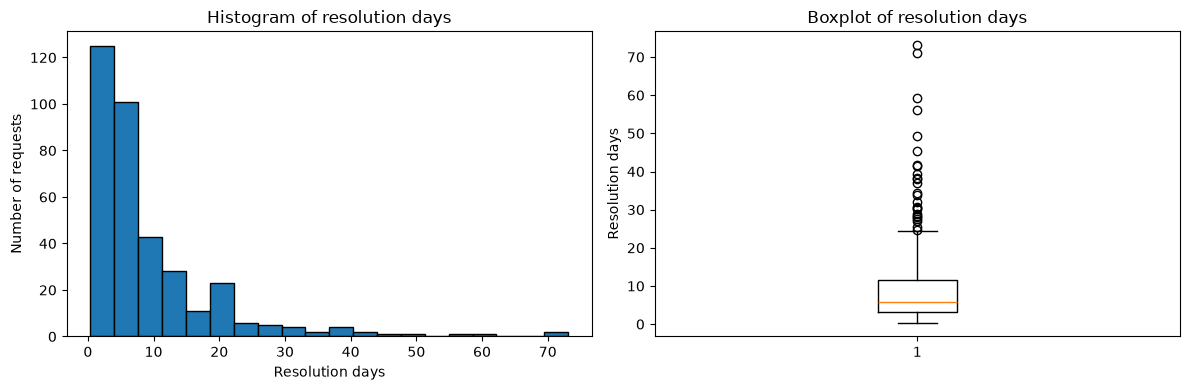

In [18]:
print("Skewness:", round(days.skew(), 2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histogram
axes[0].hist(days, bins=20, edgecolor="black")
axes[0].set_title("Histogram of resolution days")
axes[0].set_xlabel("Resolution days")
axes[0].set_ylabel("Number of requests")

# Boxplot
axes[1].boxplot(days, orientation="vertical")
axes[1].set_title("Boxplot of resolution days")
axes[1].set_ylabel("Resolution days")

plt.tight_layout()
plt.show()


## Your written answer for PA0104

- Is the distribution left-skewed, right-skewed or roughly symmetric?
- How do the histogram and the mean-vs-median comparison support that?
- What do the boxplot outliers mean in this business context?

1. Is the distribution left-skewed, right-skewed or roughly symmetric?
The distribution of resolution days is right-skewed (positively skewed), with a skewness value of 2.8. This indicates that most service requests are resolved within a relatively short period, while a smaller number take significantly longer to complete.

2. How do the histogram and mean-vs-median comparison support that?
The histogram shows that most service requests are concentrated around the lower resolution times, with a long tail extending towards higher resolution times.

The mean resolution time is 9.31 days, while the median is 5.85 days. Since the mean is considerably higher than the median, this suggests that a few unusually long resolution times are pulling the average upwards.

Both the histogram and the mean-versus-median comparison support the conclusion that the distribution is right-skewed.

3. What do the boxplot outliers mean in this business context?
The boxplot outliers represent service requests that took unusually long to resolve compared with most other requests.

In the CityConnect business context, these outliers could indicate operational challenges such as:
- Delays in assigning technicians to service requests.
- Shortages of equipment, materials or other resources.
- Complex water, electricity or road maintenance problems.
- Poor coordination between municipal departments.
- Delays in completing investigations or closing service requests.
Management should investigate these unusually long resolution times to identify the causes of delays and determine where operational improvements are needed.

Conclusion
The analysis shows that CityConnect generally resolves most service requests within a shorter period, but a smaller number of requests experience significant delays. Management should focus on investigating these extreme cases to improve operational efficiency, reduce resolution times and increase resident satisfaction.


# PA0105 — Step 5: Compare data from different groups

Averages for the whole city can hide problems.

Compare **service types** first, then **regions**.

Look at:

- count (sample size in that group)
- mean
- median
- standard deviation


In [19]:
by_service = (
    resolved.groupby("service_type")["resolution_days"]
    .agg(count="count", mean="mean", median="median", std="std")
    .round(2)
    .sort_values("mean")
)
display(by_service)

by_region = (
    resolved.groupby("region")["resolution_days"]
    .agg(count="count", mean="mean", median="median", std="std")
    .round(2)
    .sort_values("mean")
)
display(by_region)


,count,mean,median,std
service_type,,,,
Waste,66,3.44,3.10,1.95
Sanitation,55,4.82,3.60,3.61
Electricity,72,7.56,5.85,6.79
Roads,67,11.21,8.30,9.58
Water,100,15.64,12.05,14.29


,count,mean,median,std
region,,,,
CBD,58,6.13,4.35,6.19
North,80,7.75,5.35,8.46
East,75,8.38,6.50,6.91
West,59,11.01,6.10,12.81
South,88,12.48,7.15,13.38


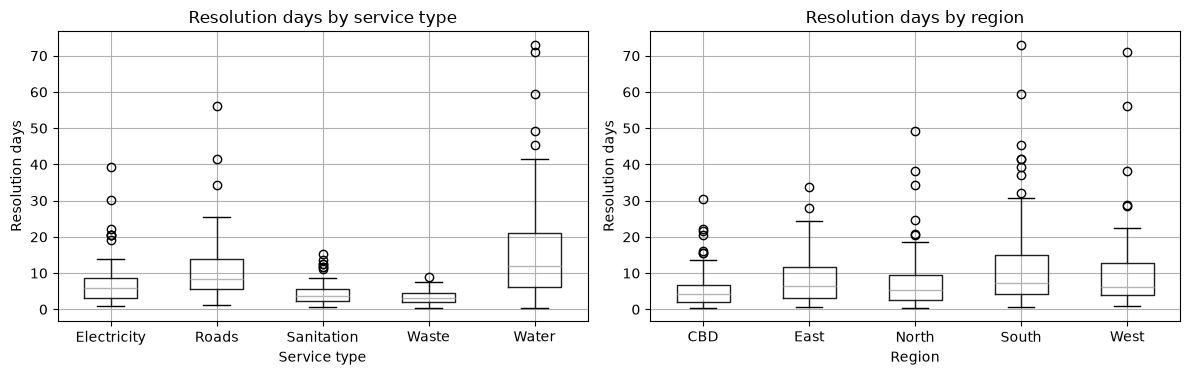

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

resolved.boxplot(column="resolution_days", by="service_type", ax=axes[0])
axes[0].set_title("Resolution days by service type")
axes[0].set_xlabel("Service type")
axes[0].set_ylabel("Resolution days")

resolved.boxplot(column="resolution_days", by="region", ax=axes[1])
axes[1].set_title("Resolution days by region")
axes[1].set_xlabel("Region")
axes[1].set_ylabel("Resolution days")

plt.suptitle("")
plt.tight_layout()
plt.show()


## Activity

Which service type is slowest? Which region is slowest?

Write two sentences management can use. Support both with median **and** mean, not only one number.


## Your written answer for PA0105

- Fastest service type:
- Slowest service type:
- Fastest region:
- Slowest region:
- Recommendation for management:

1. Fastest service type - Waste management is the fastest service type, with:
- Mean resolution time: 3.44 days.
- Median resolution time: 3.10 days.
This indicates that Waste requests are generally resolved faster than other service types.

2. Slowest service type - Water services are the slowest service type, with:
- Mean resolution time: 15.64 days.
- Median resolution time: 12.05 days.
This suggests that water-related service requests take considerably longer to resolve and may require management attention.

3. Fastest region - CBD is the fastest region, with:
- Mean resolution time: 6.13 days.
- Median resolution time: 4.35 days.
This indicates that service requests in the CBD are generally resolved faster than in other regions.

4. Slowest region - South is the slowest region, with:
- Mean resolution time: 12.48 days.
- Median resolution time: 7.15 days.
This suggests that service requests in the South experience longer resolution times compared with other regions.

5. Recommendation for management
- I recommend that CityConnect management prioritise improvements in the Water service department because it has the highest mean and median resolution times among all service types.
- Management should also investigate service delivery challenges in the South region, which has the highest average resolution time and median resolution time among all regions.

- The Waste department and CBD region demonstrate comparatively faster resolution times and could provide useful examples of effective operational practices.Management should use both the mean and median when monitoring performance. The mean helps identify the impact of unusually long delays, while the median provides a better indication of the typical resolution time.

- Additional resources, improved scheduling, better coordination between departments and regular monitoring of unresolved requests could help reduce delays and improve resident satisfaction.


# Final outputs

Export your group comparison tables so they sit next to this notebook in GitHub.


In [21]:
by_service.to_csv(OUTPUT_FOLDER / "resolution_by_service_type.csv")
by_region.to_csv(OUTPUT_FOLDER / "resolution_by_region.csv")

overall = pd.DataFrame([{
    "analysis_sample": len(resolved),
    "mean_resolution_days": round(days.mean(), 2),
    "median_resolution_days": round(days.median(), 2),
    "range": round(days.max() - days.min(), 2),
    "iqr": round(days.quantile(0.75) - days.quantile(0.25), 2),
    "std": round(days.std(), 2),
    "skewness": round(days.skew(), 2),
}])
overall.to_csv(OUTPUT_FOLDER / "overall_summary.csv", index=False)

print("Saved files in the outputs folder:")
for path in sorted(OUTPUT_FOLDER.glob("*.csv")):
    print("-", path.name)


Saved files in the outputs folder:
- overall_summary.csv
- resolution_by_region.csv
- resolution_by_service_type.csv


# Before you submit

1. Restart the kernel and run all cells from top to bottom.
2. Check that the three CSV files exist in `outputs/`.
3. Put this notebook, the original CSV, the `outputs` folder and a README in a public GitHub repository.
4. Record a 5–10 minute Loom video walking through PA0101 to PA0105.

## README checklist

Your README must explain:

- the business problem
- the dataset
- why Open requests were excluded from the analysis sample
- the five analysis steps
- your main finding
- how to run the notebook
